# Step 1: data pre-processing and history timeline
**BT4222 Group 5 · Impression-Aware Re-ranking of Search Results on JD.com**

Loads the raw JDsearch files, parses the packed columns, removes the label-ordering leak, converts every history event's time gaps into its age before the test query, and writes clean parquet files for modelling. Section 3 traces the history timeline raised in the interim feedback and records how far back each interaction type is kept, so step 2 can build features that respect it. Section 4 reproduces the interim report's statistics.

| | |
|---|---|
| **Inputs** | `JDsearch_rawData/user_behavior_data.txt`, `JDsearch_rawData/product_meta_data.txt` |
| **Outputs** | All under `JDsearch_rawData/processed/`: `parquet/user_behavior_*.parquet`, `parquet/product_meta_*.parquet`, `artifacts/history_windows.json`, `results/figures/step1_history_timeline.png` |
| **Runtime** | CPU, standard RAM. About 18 minutes for Run all: section 4 re-reads the raw files and takes about 11 of them, section 2 about 4½. |
| **Next** | `step2_feature_engineering.ipynb` reads the parquet files and `history_windows.json`; then `step3_baselines.ipynb`, `step4_advanced_models.ipynb` and `step5_diagnostics.ipynb` |

**How to run.** Add a shortcut to the shared `JDsearch_rawData` folder in My Drive, then Runtime → Run all. Save with outputs before committing to GitHub.

**Where things live.** The raw files at the top of `JDsearch_rawData` are only read. Everything this pipeline writes goes to `JDsearch_rawData/processed/`, and every later step reads from there. Only one person should run step 1 at a time: two runs writing the same files at once make Drive keep both copies.

## Roles of the data fields
Each row is one user and one test query. The fields play different roles, and the history fields are not all observed over the same period.

| Field | Role | What it holds | Observed over |
|---|---|---|---|
| `query` | Context | Term ids of the current search | The test query |
| `candidate_wid_list` | Candidate set | Every product JD displayed for this query (the impressions) | The test query |
| `candidate_label_list` | **Target** | Highest interaction per candidate: 0 none, 1 click, 2 cart, 3 purchase. The only field with real negatives | The test query |
| `history_wid_list`, `history_type_list` | Input: user state | Past interactions only (CLICK, CART, ORD, FLW): positive feedback, no impressions | A different window per type, measured in section 3 |
| `history_time_list` | Input: timing | Seconds since the previous event; the first value is 0 and the last is the gap to the test query | As above |
| `history_qry_list` | Input: intent link | Term ids of the search behind each past interaction, -1 when there was none | As above |
| Product metadata | Input: content | Name, brand, shop and four category levels; works for cold items too (missing for 0.68% of candidates) | Static |

What this means downstream: labels are only ever the target, so any statistic built from them uses training users and is computed out of fold. History can describe a user but never supplies negatives or exposures. And any feature that compares interaction types has to stay inside the period where all of them are recorded.

## 0. Setup

In [1]:
import os, glob, json
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.compute as pc
from IPython.display import display, HTML

try:                                   # Colab: mount Drive. Elsewhere: set JD_BASE instead
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

BASE = os.environ.get("JD_BASE", "/content/drive/MyDrive/JDsearch_rawData")   # shared team folder: raw files, read only
assert os.path.isdir(BASE), f"{BASE} not found: add a shortcut to JDsearch_rawData in My Drive"
PROC = os.path.join(BASE, "processed")               # everything the pipeline writes lives under here
OUT = os.path.join(PROC, "parquet")                  # parquet written by this notebook
ART = os.path.join(PROC, "artifacts")                # small files read by later steps
FIG = os.path.join(PROC, "results", "figures")       # figures for the report
for d in (OUT, ART, FIG):
    os.makedirs(d, exist_ok=True)

def parts(prefix):
    """Parquet parts written by step 1. Refuses Drive's duplicate copies (e.g. 'name (1).parquet'),
    which appear when two runs write the same files at once, instead of silently reading them twice."""
    files = sorted(glob.glob(os.path.join(OUT, f"{prefix}_*.parquet")))
    copies = [os.path.basename(f) for f in files if " (" in os.path.basename(f)]
    assert not copies, f"duplicate copies in {OUT}: {copies[:3]}. Delete them or re-run the cell that writes {prefix}"
    return files

def show_result(title, obj=None, note=""):
    """Red RESULT banner, then the table, so key outputs stand out in the saved notebook."""
    extra = f'<div style="font-size:90%;margin-top:3px">{note}</div>' if note else ""
    display(HTML('<div style="border-left:6px solid #c0392b;background:#fbeaea;color:#1f1f1f;'
                 'padding:8px 12px;margin:12px 0 4px 0;font-family:Arial,sans-serif">'
                 f"<b>RESULT</b> &nbsp;|&nbsp; {title}{extra}</div>"))
    if obj is not None:
        display(obj)

TERM_SEP = "\x18"                                     # separates terms inside a query or product name
TYPE_CODE = {"CLICK": 1, "CART": 2, "ORD": 3, "FLW": 4}
user_path = sorted(glob.glob(os.path.join(BASE, "user_behavior_data.*")))[0]
with open(user_path) as f:
    col_sep = "\t" if "\t" in f.readline() else ","
print("raw (read only):", BASE)
print("outputs:       ", PROC)

Mounted at /content/drive
raw (read only): /content/drive/MyDrive/JDsearch_rawData
outputs:        /content/drive/MyDrive/JDsearch_rawData/processed


## 1. Parse, de-leak and convert to parquet

Three separator levels apply in the raw file. Tab splits columns, `_` splits list items, and the control character `\x18` (ASCII 24) splits terms inside a query or a product name.

`history_time_list` is in **seconds**. Each value is the time since the previous event, the first value is always 0, and the list ends with the gap from the last event to the test query, so it is one element longer than the other history columns.

Four things happen while streaming, in 20,000-row chunks.

**Ordering leak removed.** In the raw file, every slate that contains a positive lists its positives first (98.79% of all rows), so list position encodes the label. Each slate is shuffled with a fixed seed, using the same seed and call order as before so the shuffle is unchanged.

**Event ages.** An event's age before the test query is the sum of all the gaps after it. For `0_86400_172800_43200` the three events are 3.5, 2.5 and 0.5 days old. Stored as `history_age_days`.

**Search flag.** `history_has_query` marks events with a search behind them (`history_qry_list` not -1). The packed query strings stay in `history_qry_packed` for term-level work.

**Compact types.** Product and term ids are int64, labels int8 (0 none, 1 click, 2 cart, 3 purchase), history types int8 (1 CLICK, 2 CART, 3 ORD, 4 FLW), ages float32. `history_gaps` keeps the opening 0, so drop each user's first gap before computing gap statistics.

In [2]:
rng = np.random.default_rng(42)          # same seed and call order as the original run: identical shuffle

def parse_chunk(chunk, start_uid):
    out = pd.DataFrame()
    out["user_id"] = np.arange(start_uid, start_uid + len(chunk))
    out["query_terms"] = [np.array(q.split(TERM_SEP), dtype=np.int64) for q in chunk["query"]]
    cand_w, cand_l = [], []
    for wids_s, labs_s in zip(chunk["candidate_wid_list"], chunk["candidate_label_list"]):
        wids = np.array(wids_s.split("_"), dtype=np.int64)
        labs = np.array(labs_s.split("_"), dtype=float).astype(np.int8)
        idx = rng.permutation(len(wids))                     # remove the ordering leak
        cand_w.append(wids[idx])
        cand_l.append(labs[idx])
    out["candidate_wids"] = cand_w
    out["candidate_labels"] = cand_l
    out["history_wids"] = [np.array(s.split("_"), dtype=np.int64) for s in chunk["history_wid_list"]]
    out["history_types"] = [np.array([TYPE_CODE[t] for t in s.split("_")], dtype=np.int8)
                            for s in chunk["history_type_list"]]
    gaps, to_query, ages = [], [], []
    for s in chunk["history_time_list"]:
        g = np.array(s.split("_"), dtype=float).astype(np.int64)   # seconds: g[0] = 0, g[-1] = gap to the query
        gaps.append(g[:-1])
        to_query.append(g[-1])
        ages.append((np.cumsum(g[::-1])[::-1][1:] / 86_400).astype(np.float32))   # event j: sum(g[j+1:])
    out["history_gaps"] = gaps
    out["gap_to_test_query"] = to_query
    out["history_age_days"] = ages
    out["history_has_query"] = [np.array([q != "-1" for q in s.split("_")]) for s in chunk["history_qry_list"]]
    out["history_qry_packed"] = chunk["history_qry_list"].values
    return out

for old in glob.glob(os.path.join(OUT, "user_behavior_*.parquet")):   # no stale parts from earlier runs
    os.remove(old)
total = 0
for i, chunk in enumerate(pd.read_csv(user_path, sep=col_sep, dtype=str, chunksize=20_000)):
    part = parse_chunk(chunk, total)
    part.to_parquet(os.path.join(OUT, f"user_behavior_{i:02d}.parquet"), index=False)
    total += len(chunk)
    print(f"part {i:02d}: {total:,} rows")
print(f"done: {total:,} rows")

part 00: 20,000 rows
part 01: 40,000 rows
part 02: 60,000 rows
part 03: 80,000 rows
part 04: 100,000 rows
part 05: 120,000 rows
part 06: 140,000 rows
part 07: 160,000 rows
part 08: 173,831 rows
done: 173,831 rows


## 2. Product metadata to parquet

Converts the 12,141,247-row `product_meta_data` file into parquet parts, processed in chunks. ID columns (`wid`, `brand_id`, `shop_id`, `cate_id_1` to `cate_id_4`) are written as int64, with -1 where missing, so joins in later steps need no conversion. Name, brand-name and category-name fields stay as packed strings of term ids.

In [3]:
ID_COLS = ["wid", "brand_id", "shop_id", "cate_id_1", "cate_id_2", "cate_id_3", "cate_id_4"]
prod_glob = sorted(glob.glob(os.path.join(BASE, "product_meta_data.*")))
if not prod_glob:
    print("product_meta_data not uploaded yet: skipping this step")
else:
    prod_path = prod_glob[0]
    with open(prod_path) as f:
        prod_sep = "\t" if "\t" in f.readline() else ","
    for old in glob.glob(os.path.join(OUT, "product_meta_*.parquet")):
        os.remove(old)
    total = 0
    for i, chunk in enumerate(pd.read_csv(prod_path, sep=prod_sep, dtype=str, chunksize=2_000_000)):
        for c in ID_COLS:
            chunk[c] = pd.to_numeric(chunk[c], errors="coerce").fillna(-1).astype(np.int64)
        chunk.to_parquet(os.path.join(OUT, f"product_meta_{i:02d}.parquet"), index=False)
        total += len(chunk)
        print(f"chunk {i}: {total:,} rows written")
    print(f"done: {total:,} products")

chunk 0: 2,000,000 rows written
chunk 1: 4,000,000 rows written
chunk 2: 6,000,000 rows written
chunk 3: 8,000,000 rows written
chunk 4: 10,000,000 rows written
chunk 5: 12,000,000 rows written
chunk 6: 12,141,247 rows written
done: 12,141,247 products


In [4]:
# validation: reload the parquet parts, check the known totals and the new time fields
files = parts("user_behavior")
back = pa.concat_tables([pq.read_table(f, columns=["candidate_labels", "history_wids", "history_types",
                         "history_gaps", "history_age_days", "history_has_query"]) for f in files])
assert back.num_rows == 173_831, f"unexpected row count {back.num_rows}"

labels_flat = pc.list_flatten(back["candidate_labels"]).to_numpy()
label_counts = pd.Series(labels_flat).value_counts().sort_index()
print(label_counts)
# expected: 0 -> 15,189,116 | 1 -> 224,487 | 2 -> 75,573 | 3 -> 20,836
assert label_counts[1] == 224_487

n_cand = pc.list_value_length(back["candidate_labels"]).to_numpy()
first_label = labels_flat[np.cumsum(n_cand) - n_cand]
print(f"positives in position 1 after shuffle: {np.mean(first_label > 0):.2%} (was 98.79% in the raw file)")

n_ev = pc.list_value_length(back["history_wids"]).to_numpy()
aligned = all(np.array_equal(pc.list_value_length(back[c]).to_numpy(), n_ev)
              for c in ("history_types", "history_gaps", "history_age_days", "history_has_query"))
gaps = pc.list_flatten(back["history_gaps"]).to_numpy()
age = pc.list_flatten(back["history_age_days"]).to_numpy()
first = np.cumsum(n_ev) - n_ev                         # position of each user's oldest event
step = np.diff(age)
step[first[1:] - 1] = 0                                # ignore steps that cross into the next user
checks = pd.Series({
    "history lists aligned": aligned,
    "every time list starts with 0": bool((gaps[first] == 0).all()),
    "ages never increase along a history": bool((step <= 0).all()),
}, name="passed")
display(checks.to_frame())
assert checks.all(), "a structural check failed: inspect before continuing"
print(f"history events {len(age):,} | oldest event {age.max():.1f} days | label dtype {labels_flat.dtype}")

# The paper describes a one-year window, but some events are older. Report them rather than fail:
# section 3 shows where they sit, and its window rule is not stretched by a thin tail.
old = age > 365
types_flat = pc.list_flatten(back["history_types"]).to_numpy()
owner = np.repeat(np.arange(len(n_ev)), n_ev)
print(f"events older than 365 days: {old.sum():,} ({old.mean():.3%}) from {np.unique(owner[old]).size:,} users")
if old.any():
    display(pd.DataFrame({"type": pd.Series(types_flat[old]).map({1: "CLICK", 2: "CART", 3: "ORD", 4: "FLW"}),
                          "age_days": age[old]})
              .groupby("type")["age_days"].describe(percentiles=[0.5, 0.9]).round(1))
print("validation passed")
del back, labels_flat, gaps, age, step, old, types_flat, owner

0    15189116
1      224487
2       75573
3       20836
Name: count, dtype: int64
positives in position 1 after shuffle: 3.01% (was 98.79% in the raw file)


,passed
history lists aligned,True
every time list starts with 0,True
ages never increase along a history,True


history events 26,667,260 | oldest event 635.3 days | label dtype int8
events older than 365 days: 1 (0.000%) from 1 users


,count,mean,std,min,50%,90%,max
type,,,,,,,
CART,1.0,635.3,NaN,635.3,635.3,635.3,635.3


validation passed


## 3. History timeline: how far back is each interaction type kept?

**Why.** The pooled history holds more carts (11.5M) than clicks (8.3M) and almost as many orders (6.8M) as clicks. In a normal funnel clicks outnumber carts 5 to 10 times and carts outnumber orders 3 to 5 times, and the test-day labels of these same users do follow a normal funnel. The interim put this down to carting straight from search results. The feedback asked us to check it against time instead: convert the gaps to days before the test query and watch the mix of clicks, carts and orders further back.

**Approach.** Every event's age comes from section 1. We count each type by age bucket, find how far back each type goes, check whether older carts and orders still have the click that came before them, and compare the funnel inside and outside the period where clicks are recorded.

**Output.** `artifacts/history_windows.json`, the number of days each type is kept. Steps 2 and 3 read it, so baseline segments and features use the same cutoffs.

In [5]:
# 3.1 Every history event with its age, one row per event
hist_tbl = pa.concat_tables([pq.read_table(f, columns=["user_id", "history_wids", "history_types", "history_gaps",
                             "history_age_days", "history_has_query"]) for f in files])
n_ev = pc.list_value_length(hist_tbl["history_wids"]).to_numpy()
ev = pd.DataFrame({
    "user_id": np.repeat(hist_tbl["user_id"].to_numpy(), n_ev).astype(np.int32),
    "wid": pc.list_flatten(hist_tbl["history_wids"]).to_numpy(),
    "type": pc.list_flatten(hist_tbl["history_types"]).to_numpy(),
    "age_days": pc.list_flatten(hist_tbl["history_age_days"]).to_numpy(),
    "has_query": np.asarray(pc.list_flatten(hist_tbl["history_has_query"])),
})
gaps = pc.list_flatten(hist_tbl["history_gaps"]).to_numpy()
first = np.cumsum(n_ev) - n_ev                         # position of each user's oldest event
del hist_tbl
TYPES = {1: "CLICK", 2: "CART", 3: "ORD", 4: "FLW"}
print(f"{len(ev):,} history events from {len(n_ev):,} users")

26,667,260 history events from 173,831 users


type,CLICK,CART,ORD,FLW,click share,clicks per cart,carts per order
age_bucket,,,,,,,
0-1d,"1,918,289","287,228","36,441",616,85.5%,6.68,7.88
1-3d,"2,534,453","375,715","57,033",629,85.4%,6.75,6.59
3-7d,"3,846,045","672,214","109,348","1,406",83.1%,5.72,6.15
7-14d,107,"1,068,418","175,040","2,210",0.0%,0.00,6.10
14-30d,0,"2,232,532","377,968","5,209",0.0%,0.00,5.91
30-60d,0,"3,935,547","697,945","7,959",0.0%,0.00,5.64
60-90d,0,"2,953,646","582,150","6,550",0.0%,0.00,5.07
90-120d,0,"1,173","576,709",0,0.0%,0.00,0.00
120-180d,0,30,"1,247,417",0,0.0%,0.00,0.00


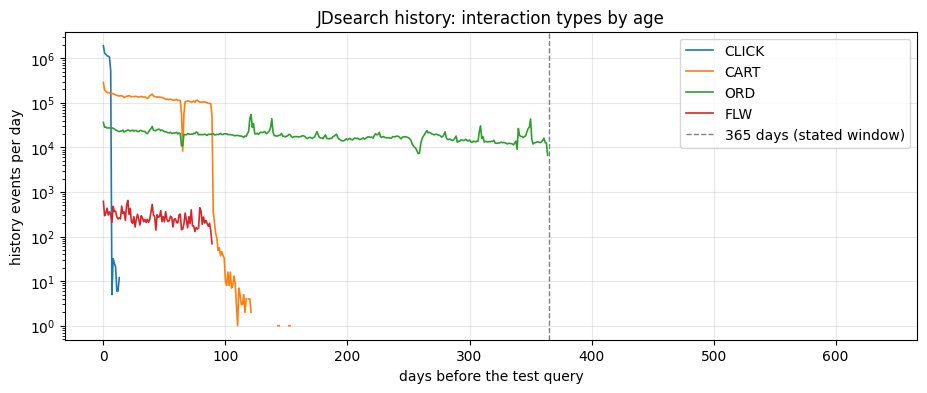

In [6]:
# 3.2 Mix of interaction types by age before the test query
import matplotlib.pyplot as plt
EDGES = [0, 1, 3, 7, 14, 30, 60, 90, 120, 180, 270, 365, np.inf]
BUCKETS = [f"{a}-{b}d" for a, b in zip(EDGES[:-2], EDGES[1:-1])] + ["365d+"]
ev["age_bucket"] = pd.cut(ev["age_days"], EDGES, right=False, labels=BUCKETS)
mix = (pd.crosstab(ev["age_bucket"], ev["type"])
         .reindex(index=BUCKETS, columns=list(TYPES), fill_value=0).rename(columns=TYPES))
mix["click share"] = mix["CLICK"] / mix[list(TYPES.values())].sum(axis=1)
mix["clicks per cart"] = mix["CLICK"] / mix["CART"].replace(0, np.nan)
mix["carts per order"] = mix["CART"] / mix["ORD"].replace(0, np.nan)
show_result("Interaction types by age before the test query", mix.style.format("{:,.0f}", subset=list(TYPES.values()))
           .format("{:.1%}", subset=["click share"])
           .format("{:.2f}", subset=["clicks per cart", "carts per order"], na_rep="-"))

day = ev["age_days"].to_numpy().astype(int)
n_days = int(day.max()) + 1
daily = np.bincount(day * 4 + ev["type"].to_numpy().astype(int) - 1, minlength=n_days * 4).reshape(n_days, 4)
fig, ax = plt.subplots(figsize=(11, 4))
for k, name in enumerate(TYPES.values()):
    ax.plot(np.arange(n_days), np.where(daily[:, k] > 0, daily[:, k], np.nan), label=name, lw=1.2)
ax.axvline(365, color="grey", ls="--", lw=1, label="365 days (stated window)")
ax.set_yscale("log"); ax.set_xlabel("days before the test query"); ax.set_ylabel("history events per day")
ax.set_title("JDsearch history: interaction types by age"); ax.legend(); ax.grid(alpha=0.3)
fig.savefig(os.path.join(FIG, "step1_history_timeline.png"), dpi=200, bbox_inches="tight")
plt.show()

In [7]:
# 3.3 How far back does each type go?  A hard cutoff shows as a cliff in the plot: the daily
# event rate collapses from one day to the next and only a thin tail of older events remains.
# Window per type = the first day where the next week's daily rate falls below 5% of the previous
# month's. If a type has no such cliff (or too few events to judge), fall back to its p99.9 age.
def cliff_day(counts, drop=0.05, after=7, before=30, min_events=1_000):
    if counts.sum() < min_events:
        return None
    cs = np.concatenate([[0], np.cumsum(counts)])
    for d in range(1, len(counts)):
        prev = (cs[d] - cs[max(0, d - before)]) / min(d, before)
        nxt = (cs[min(len(counts), d + after)] - cs[d]) / max(1, min(after, len(counts) - d))
        if prev > 0 and nxt < drop * prev:
            return d
    return None

reach_rows = {}
for t, name in TYPES.items():
    sub = ev.loc[ev["type"] == t, ["user_id", "age_days"]]
    if sub.empty:
        continue
    a = np.sort(sub["age_days"].to_numpy())
    oldest = sub.groupby("user_id")["age_days"].max()
    p999 = float(np.quantile(a, 0.999))
    cliff = cliff_day(daily[:, t - 1])
    window_days = cliff if cliff is not None else int(np.ceil(p999))
    reach_rows[name] = {"events": len(a),
                        **{f"< {d}d": np.searchsorted(a, d) / len(a) for d in (1, 3, 7, 14, 30, 90, 180, 365)},
                        "p99.9 age": p999, "max age": float(a[-1]),
                        "cliff (day)": np.nan if cliff is None else cliff, "window (days)": window_days,
                        "older than window": 1 - np.searchsorted(a, window_days, side="right") / len(a),
                        "users": len(oldest), "user oldest p50": oldest.median(), "user oldest p99": oldest.quantile(0.99)}
reach = pd.DataFrame(reach_rows).T
share_cols = [c for c in reach.columns if c.startswith("<")] + ["older than window"]
show_result("How far back each interaction type is kept (the history windows)", reach.style.format("{:.1%}", subset=share_cols)
             .format("{:,.1f}", subset=["p99.9 age", "max age", "user oldest p50", "user oldest p99"])
             .format("{:,.0f}", subset=["events", "users", "window (days)", "cliff (day)"], na_rep="none"))

# Check against the plot. If the cliff for a type sits elsewhere, set it by hand here,
# e.g. HISTORY_WINDOWS["CLICK"] = 7, before saving.
HISTORY_WINDOWS = {name: int(reach.loc[name, "window (days)"]) for name in reach.index}
print("history windows (days):", HISTORY_WINDOWS)

with open(os.path.join(ART, "history_windows.json"), "w") as f:
    json.dump({"windows_days": HISTORY_WINDOWS,
               "rule": "first day the daily event rate drops below 5% of the previous month's (p99.9 age if no cliff), checked against the step-1 plot",
               "evidence": {name: {k: (None if pd.isna(v) else v) for k, v in row.items()}
                            for name, row in reach[["events", "p99.9 age", "max age", "cliff (day)", "older than window"]]
                                             .astype(float).round(4).to_dict(orient="index").items()}}, f, indent=2)
print("saved", os.path.join(ART, "history_windows.json"))

,events,< 1d,< 3d,< 7d,< 14d,< 30d,< 90d,< 180d,< 365d,p99.9 age,max age,cliff (day),window (days),older than window,users,user oldest p50,user oldest p99
CLICK,"8,298,894",23.1%,53.7%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,6.9,13.1,7,7,0.0%,"145,647",5.0,6.8
CART,"11,526,504",2.5%,5.8%,11.6%,20.9%,40.2%,100.0%,100.0%,100.0%,89.5,635.3,90,90,0.0%,"166,382",81.6,89.8
ORD,"6,817,283",0.5%,1.4%,3.0%,5.5%,11.1%,29.9%,56.6%,100.0%,364.0,365.0,365,365,0.0%,"159,145",308.7,364.3
FLW,"24,579",2.5%,5.1%,10.8%,19.8%,41.0%,100.0%,100.0%,100.0%,89.4,90.0,89,89,0.3%,"2,139",45.9,89.1


history windows (days): {'CLICK': 7, 'CART': 90, 'ORD': 365, 'FLW': 89}
saved /content/drive/MyDrive/JDsearch_rawData/processed/artifacts/history_windows.json


In [8]:
# 3.4 Do older carts and orders still have the click that came before them?
key = ev["user_id"].to_numpy().astype(np.int64) * (int(ev["wid"].max()) + 1) + ev["wid"].to_numpy()
has_click = np.isin(key, np.unique(key[ev["type"].to_numpy() == 1]))   # this user clicked this item at some point
co = ev["type"].isin([2, 3]).to_numpy()
noclick = (ev.loc[co, ["age_bucket", "type"]].assign(no_click=~has_click[co])
             .pivot_table(index="age_bucket", columns="type", values="no_click", aggfunc="mean", observed=False)
             .rename(columns=TYPES))
show_result("Carts and orders with no click on the same item, by age", noclick.style.format("{:.1%}", na_rep="-").set_caption("share of carts and orders with no click on that item"))
print(f"carts and orders with no click on that item anywhere in the user's history: "
      f"{(~has_click[co]).sum():,} of {co.sum():,} ({(~has_click[co]).mean():.1%})")

type,CART,ORD
age_bucket,,
0-1d,17.3%,23.2%
1-3d,16.0%,21.0%
3-7d,25.7%,30.0%
7-14d,89.9%,88.5%
14-30d,95.0%,95.4%
30-60d,97.3%,97.2%
60-90d,98.1%,97.9%
90-120d,97.8%,98.5%
120-180d,83.3%,98.4%


carts and orders with no click on that item anywhere in the user's history: 16,626,591 of 18,343,787 (90.6%)


In [9]:
# 3.5 Funnel inside the click window vs older history vs the test-day labels, and gaps by zone
W_CLICK = HISTORY_WINDOWS["CLICK"]
inside = ev["age_days"].to_numpy() < W_CLICK

def funnel(mask):
    c = np.bincount(ev["type"].to_numpy()[mask].astype(int), minlength=5)
    return {"clicks": c[1], "carts": c[2], "orders": c[3],
            "clicks per cart": c[1] / max(c[2], 1), "carts per order": c[2] / max(c[3], 1)}

lab = pc.list_flatten(pa.concat_tables([pq.read_table(f, columns=["candidate_labels"]) for f in files])
                      ["candidate_labels"]).to_numpy()
test_day = {"clicks": int((lab >= 1).sum()), "carts": int((lab >= 2).sum()), "orders": int((lab == 3).sum())}
test_day["clicks per cart"] = test_day["clicks"] / test_day["carts"]
test_day["carts per order"] = test_day["carts"] / test_day["orders"]
funnels = pd.DataFrame({f"history, last {W_CLICK} days": funnel(inside),
                        f"history, older than {W_CLICK} days": funnel(~inside),
                        "history, all ages pooled": funnel(np.ones(len(ev), bool)),
                        "test-day labels (engaged, cart+, purchase)": test_day}).T
show_result("Funnel inside the click window, in older history and in the test-day labels", funnels.style.format("{:,.0f}", subset=["clicks", "carts", "orders"])
                .format("{:.2f}", subset=["clicks per cart", "carts per order"]))

inner = np.ones(len(gaps), bool)
inner[first] = False                                   # drop the structural 0 that opens every list
zone = inside[inner]                                   # zone of the later event in each consecutive pair
quant = lambda x: pd.Series(np.quantile(x, [0.25, 0.5, 0.75, 0.9]) if len(x) else [np.nan] * 4,
                            index=["p25", "median", "p75", "p90"])
gap_table = pd.DataFrame({f"inside last {W_CLICK} days": quant(gaps[inner][zone]),
                          f"older than {W_CLICK} days": quant(gaps[inner][~zone]),
                          "all gaps": quant(gaps[inner])}).T
show_result("Time between consecutive history events", gap_table.style.format("{:,.0f}").set_caption("seconds between consecutive history events"))
del ev, key, has_click, co, lab, gaps, inner, zone, day, daily

,clicks,carts,orders,clicks per cart,carts per order
"history, last 7 days","8,298,787","1,335,157","202,822",6.22,6.58
"history, older than 7 days",107,"10,191,347","6,614,461",0.00,1.54
"history, all ages pooled","8,298,894","11,526,504","6,817,283",0.72,1.69
"test-day labels (engaged, cart+, purchase)","320,896","96,409","20,836",3.33,4.63


,p25,median,p75,p90
inside last 7 days,8,22,66,"1,666"
older than 7 days,26,246,"66,260","412,701"
all gaps,12,67,"7,603","212,370"


**Reading the results.**
* **Each interaction type is kept for a different period.** Clicks stop at 7 days (107 of 8,298,894 clicks are older, none older than 14 days), carts at 90 days and orders at 365 days; follows stop at 89 days. The cliff rule in 3.3 and the plot agree, and `history_windows.json` records these windows.
* **Older carts and orders have lost the click before them.** 90.6% of carts and orders (16.6M of 18.3M) have no click on that item anywhere in the user's history. Inside the last 7 days, where clicks are still kept, the share is 16–30%; beyond it, 88–99%. The clicks were dropped from the log, not skipped by the user.
* **Inside the click window the funnel is normal.** The last 7 days give 6.22 clicks per cart and 6.58 carts per order, within the 5–10 and 3–5 the feedback quotes. Pooled over all ages the ratios invert to 0.72 and 1.69, which is the pattern the interim reported. The test-day labels give 3.33 and 4.63.
* **For the report.** The inverted funnel is a logging artefact of three different retention windows, not user behaviour. This replaces the interim's "carting straight from search results" explanation in Section 1, and it is why no step-2 model feature compares types outside the period where all of them are recorded.


## 4. Report statistics

Every figure quoted in the interim report is computed and printed by the cells below. Order-sensitive statistics read the raw file, since the parquet slates are shuffled.

The one exception is the collection window (2021-10-18 to 2022-10-17), which is not derivable from the files and is cited from the JDsearch paper (Liu et al., SIGIR 2023, section 3). The files do not match it exactly: the validation cell counts the history events older than 365 days.

Two interim statements are superseded by section 3: the explanation for carts outnumbering clicks, and the time-gap statistics. The old gap figures sampled each user's oldest 50 gaps, including the opening 0, so they came mostly from the part of the history where clicks are no longer kept. Gap statistics now come from section 3.5.

In [10]:
# behaviour file: slates, funnel, histories, queries, time gaps
import csv, statistics as st
from collections import Counter
csv.field_size_limit(10**9)

slate_len, hist_len, qlen = [], [], []
labels = Counter(); htypes = Counter(); queries = Counter()
dup_hist = Counter(); npos = Counter()
zero_pos = 0; last_gap = []

with open(user_path, newline="") as f:
    for rec in csv.DictReader(f, delimiter=col_sep):
        labs = rec["candidate_label_list"].split("_")
        slate_len.append(len(labs))
        labels.update(labs)
        p = sum(l != "0.0" for l in labs)
        npos[min(p, 4)] += 1
        if p == 0:
            zero_pos += 1
        h = rec["history_type_list"].split("_")
        htypes.update(h)
        hist_len.append(len(h))
        last_gap.append(float(rec["history_time_list"].rsplit("_", 1)[-1]))   # gap from the last event to the test query
        queries[rec["query"]] += 1
        qlen.append(len(rec["query"].split(TERM_SEP)))
        dup_hist[rec["history_wid_list"]] += 1

rows = len(slate_len)
dups = sum(c - 1 for c in dup_hist.values() if c > 1)
print(f"rows (= users)             : {rows:,}")
print(f"exact-duplicate histories  : {dups:,} ({dups/rows:.3%})")
print(f"rows with zero positives   : {zero_pos:,}")
print(f"unique queries             : {len(queries):,} (repeat rate {1 - len(queries)/rows:.1%})")
print(f"query length (terms)       : mean {st.mean(qlen):.2f}, median {st.median(qlen)}, max {max(qlen)}")
print(f"slate length               : mean {st.mean(slate_len):.1f}, median {st.median(slate_len)}, max {max(slate_len)}")
print(f"history length             : mean {st.mean(hist_len):.1f}, median {st.median(hist_len)}, max {max(hist_len)}")

print("\npositives per slate")
for k in range(5):
    lbl = "4 or more" if k == 4 else str(k)
    print(f"  {lbl:<10}{npos[k]:>10,}  {npos[k]/rows:.2%}")

print("\nfunnel over all impressions")
tot = sum(labels.values())
for key, name in [("0.0","no interaction"), ("1.0","click"), ("2.0","cart"), ("3.0","purchase")]:
    print(f"  {name:<15}{labels[key]:>12,}  {labels[key]/tot:.3%}")
c1, c2, c3 = labels["1.0"], labels["2.0"], labels["3.0"]
eng = c1 + c2 + c3
print(f"  P(any engagement | impression) = {eng/tot:.3%}")
print(f"  P(cart or beyond | engaged)    = {(c2+c3)/eng:.1%}")
print(f"  P(purchase | cart or beyond)   = {c3/(c2+c3):.1%}")

print("\nhistory interaction types (pooled over every age; section 3 splits them by age)")
ht = sum(htypes.values())
for k, v in htypes.most_common():
    print(f"  {k:<7}{v:>12,}  {v/ht:.2%}")

lg = sorted(last_gap)
print(f"\ngap from last action to test query (seconds): median {lg[len(lg)//2]:,.0f}, p90 {lg[9*len(lg)//10]:,.0f}")
print("gaps between consecutive actions: see section 3.5 (split by age, opening 0 excluded)")

del dup_hist, queries, last_gap

rows (= users)             : 173,831
exact-duplicate histories  : 134 (0.077%)
rows with zero positives   : 2,103
unique queries             : 111,556 (repeat rate 35.8%)
query length (terms)       : mean 2.75, median 2, max 58
slate length               : mean 89.2, median 90, max 200
history length             : mean 153.4, median 78, max 4802

positives per slate
  0              2,103  1.21%
  1            103,192  59.36%
  2             36,064  20.75%
  3             15,185  8.74%
  4 or more     17,287  9.94%

funnel over all impressions
  no interaction   15,189,116  97.931%
  click               224,487  1.447%
  cart                 75,573  0.487%
  purchase             20,836  0.134%
  P(any engagement | impression) = 2.069%
  P(cart or beyond | engaged)    = 30.0%
  P(purchase | cart or beyond)   = 21.6%

history interaction types (pooled over every age; section 3 splits them by age)
  CART     11,526,504  43.22%
  CLICK     8,298,894  31.12%
  ORD       6,817,283  25.56%
  

In [11]:
# cold items, product coverage and popularity
hist_wids = set()
with open(user_path, newline="") as f:
    for rec in csv.DictReader(f, delimiter=col_sep):
        hist_wids.update(map(int, rec["history_wid_list"].split("_")))

cand_pop = Counter()
pos_total = pos_cold = 0
with open(user_path, newline="") as f:
    for rec in csv.DictReader(f, delimiter=col_sep):
        labs = rec["candidate_label_list"].split("_")
        for w, l in zip(rec["candidate_wid_list"].split("_"), labs):
            wi = int(w)
            cand_pop[wi] += 1
            if l != "0.0":
                pos_total += 1
                if wi not in hist_wids:
                    pos_cold += 1

cand_wids = set(cand_pop)
cold = len(cand_wids - hist_wids)
print(f"unique history products               : {len(hist_wids):,}")
print(f"unique candidate products             : {len(cand_wids):,}")
print(f"all products observed                 : {len(cand_wids | hist_wids):,}")
print(f"cold candidates (never in any history): {cold:,} ({cold/len(cand_wids):.2%})")
print(f"positives                             : {pos_total:,}")
print(f"positives on cold items               : {pos_cold:,} ({pos_cold/pos_total:.2%})")

total_imp = sum(cand_pop.values())
by_pop = sorted(cand_pop.values(), reverse=True)
for frac in (0.01, 0.10):
    k = max(1, int(len(by_pop) * frac))
    print(f"top {frac:.0%} of items take {sum(by_pop[:k])/total_imp:.1%} of {total_imp:,} impressions")
once = sum(1 for c in by_pop if c == 1)
print(f"items appearing exactly once          : {once:,} ({once/len(by_pop):.1%})")
del cand_pop, by_pop

unique history products               : 5,584,543
unique candidate products             : 8,362,535
all products observed                 : 12,319,978
cold candidates (never in any history): 6,735,435 (80.54%)
positives                             : 320,896
positives on cold items               : 86,062 (26.82%)
top 1% of items take 14.3% of 15,510,012 impressions
top 10% of items take 41.8% of 15,510,012 impressions
items appearing exactly once          : 6,286,760 (75.2%)


In [12]:
# candidate ordering in the raw file (pre-shuffle)
front = 0
pos_by_rank = Counter(); n_by_rank = Counter()
with open(user_path, newline="") as f:
    for rec in csv.DictReader(f, delimiter=col_sep):
        v = [float(x) for x in rec["candidate_label_list"].split("_")]
        pos = [i for i, x in enumerate(v) if x > 0]
        if pos and pos == list(range(len(pos))):
            front += 1
        for i, x in enumerate(v):
            n_by_rank[i] += 1
            if x > 0:
                pos_by_rank[i] += 1

print(f"rows with every positive at the front of the list: {front:,} ({front/rows:.2%})")
print("\npositive rate by raw list position")
for i in (0, 1, 2, 4, 9, 19, 49):
    print(f"  position {i+1:>3}: {pos_by_rank[i]/n_by_rank[i]:.4%}   n={n_by_rank[i]:,}")
del pos_by_rank, n_by_rank

rows with every positive at the front of the list: 171,728 (98.79%)

positive rate by raw list position
  position   1: 98.7902%   n=173,831
  position   2: 39.5376%   n=173,344
  position   3: 18.7820%   n=172,889
  position   5: 5.7974%   n=172,009
  position  10: 0.8143%   n=170,089
  position  20: 0.0581%   n=166,886
  position  50: 0.0007%   n=151,231


In [13]:
# product metadata: cardinalities, vocabularies, missing values, coverage
prod_path = sorted(glob.glob(os.path.join(BASE, "product_meta_data.*")))[0]
with open(prod_path) as f:
    prod_sep = "\t" if "\t" in f.readline() else ","

meta_wids = set()
brands = set(); shops = set()
cates = [set(), set(), set(), set()]
name_vocab = set(); brand_vocab = set(); cate_vocab = set()
name_len = Counter(); empty = Counter()
FIELDS = ["wid","name","brand_id","brand_name","cate_id_1","cate_name_1","cate_id_2",
          "cate_name_2","cate_id_3","cate_name_3","cate_id_4","cate_name_4","shop_id"]

with open(prod_path, newline="") as f:
    r = csv.reader(f, delimiter=prod_sep)
    next(r)
    for p in r:
        meta_wids.add(int(p[0]))
        for i, v in enumerate(p):
            if not v.strip():
                empty[FIELDS[i]] += 1
        brands.add(p[2]); shops.add(p[12])
        for k in range(4):
            cates[k].add(p[4 + 2*k])
        terms = p[1].split(TERM_SEP)
        name_len[len(terms)] += 1
        name_vocab.update(terms)
        brand_vocab.update(p[3].split(TERM_SEP))
        for k in range(4):
            cate_vocab.update(p[5 + 2*k].split(TERM_SEP))

print(f"products in metadata        : {len(meta_wids):,}")
print(f"distinct brands             : {len(brands):,}")
print(f"distinct shops              : {len(shops):,}")
print("distinct categories by level:", [f"{len(c):,}" for c in cates])
print(f"name term vocabulary        : {len(name_vocab):,}")
print(f"brand-name term vocabulary  : {len(brand_vocab):,}")
print(f"category-name vocabulary    : {len(cate_vocab):,}")
tot_n = sum(name_len.values()); cum = 0; med = None
for k in sorted(name_len):
    cum += name_len[k]
    if med is None and cum >= tot_n / 2:
        med = k
mean_n = sum(k * v for k, v in name_len.items()) / tot_n
print(f"product-name length (terms) : median {med}, mean {mean_n:.1f}, max {max(name_len)}")
print("empty-value counts          :", dict(empty) or "none")

missing = len(cand_wids - meta_wids)
print(f"candidates missing metadata : {missing:,} ({missing/len(cand_wids):.2%})")
del meta_wids, brands, shops, cates, name_vocab, brand_vocab, cate_vocab

products in metadata        : 12,141,247
distinct brands             : 182,585
distinct shops              : 250,935
distinct categories by level: ['76', '671', '5,819', '7,137']
name term vocabulary        : 986,404
brand-name term vocabulary  : 192,685
category-name vocabulary    : 6,125
product-name length (terms) : median 27, mean 27.9, max 78
empty-value counts          : {'brand_name': 941660}
candidates missing metadata : 56,913 (0.68%)


In [14]:
# query-term overlap versus outcome (uniform random sample of 4,000 rows, seed 0)
import random
random.seed(0)
sample = []
with open(user_path, newline="") as f:
    for i, rec in enumerate(csv.DictReader(f, delimiter=col_sep)):
        if len(sample) < 4000:
            sample.append(rec)
        else:
            j = random.randint(0, i)
            if j < 4000:
                sample[j] = rec

need = set()
for rec in sample:
    need.update(rec["candidate_wid_list"].split("_"))

meta = {}
with open(prod_path, newline="") as f:
    r = csv.reader(f, delimiter=prod_sep)
    hdr = next(r)
    ix = {c: k for k, c in enumerate(hdr)}
    for p in r:
        w = p[ix["wid"]]
        if w in need:
            name = frozenset(p[ix["name"]].split(TERM_SEP))
            brand = frozenset(p[ix["brand_name"]].split(TERM_SEP))
            cate = frozenset().union(*[p[ix[f"cate_name_{k}"]].split(TERM_SEP) for k in range(1, 5)])
            meta[w] = (name, brand, cate)
print(f"metadata resolved for {len(meta):,} of {len(need):,} sampled candidates")

from collections import defaultdict
buckets = defaultdict(lambda: [0, 0])
cold_buckets = defaultdict(lambda: [0, 0])
field = defaultdict(lambda: [0, 0])
slate_share = []
tot_c = pos_c = 0

for rec in sample:
    q = set(rec["query"].split(TERM_SEP))
    hist = set(rec["history_wid_list"].split("_"))
    wids = rec["candidate_wid_list"].split("_")
    labs = rec["candidate_label_list"].split("_")
    matched = 0
    for w, l in zip(wids, labs):
        m = meta.get(w)
        if m is None:
            continue
        name, brand, cate = m
        y = 1 if l != "0.0" else 0
        ov = q & (name | brand | cate)
        cov = len(ov) / len(q)
        b = "no overlap" if cov == 0 else ("partial" if cov < 1 else "full")
        buckets[b][0] += 1; buckets[b][1] += y
        if w not in hist:
            cold_buckets[b][0] += 1; cold_buckets[b][1] += y
        for fname, fset in (("name", name), ("brand", brand), ("category", cate)):
            key = fname + (" hit" if q & fset else " miss")
            field[key][0] += 1; field[key][1] += y
        if ov:
            matched += 1
        tot_c += 1; pos_c += y
    if wids:
        slate_share.append(matched / len(wids))

base = pos_c / tot_c
print(f"candidates scored {tot_c:,}, base positive rate {base:.2%}")
for title, d in (("coverage", buckets), ("coverage, cold items only", cold_buckets), ("field-level", field)):
    print(f"\npositive rate by {title}")
    for k in sorted(d):
        n, p = d[k]
        if n:
            print(f"  {k:<14}{n:>9,}  rate {p/n:.2%}  lift {p/n/base:.2f}x")

ss = sorted(slate_share)
print(f"\nshare of a slate matching at least one query term")
print(f"  mean {sum(ss)/len(ss):.1%}, median {ss[len(ss)//2]:.1%}, p10 {ss[len(ss)//10]:.1%}")
selective = sum(1 for s in ss if s < 0.5)
print(f"  slates with under half their candidates matching: {selective:,} of {len(ss):,} ({selective/len(ss):.1%})")

metadata resolved for 329,836 of 331,349 sampled candidates
candidates scored 353,959, base positive rate 2.03%

positive rate by coverage
  full            191,995  rate 1.97%  lift 0.97x
  no overlap       28,507  rate 1.61%  lift 0.79x
  partial         133,457  rate 2.22%  lift 1.09x

positive rate by coverage, cold items only
  full            190,691  rate 1.81%  lift 0.89x
  no overlap       28,223  rate 1.46%  lift 0.72x
  partial         132,313  rate 2.03%  lift 1.00x

positive rate by field-level
  brand hit        68,313  rate 2.23%  lift 1.09x
  brand miss      285,646  rate 1.99%  lift 0.98x
  category hit    133,939  rate 2.20%  lift 1.08x
  category miss   220,020  rate 1.93%  lift 0.95x
  name hit        319,977  rate 2.07%  lift 1.02x
  name miss        33,982  rate 1.67%  lift 0.82x

share of a slate matching at least one query term
  mean 91.8%, median 100.0%, p10 72.4%
  slates with under half their candidates matching: 238 of 4,000 (5.9%)


## 5. Outputs of this notebook

In [15]:
for folder in (OUT, ART, FIG):
    for f in sorted(glob.glob(os.path.join(folder, "*"))):
        print(f"{os.path.relpath(f, BASE):<58} {os.path.getsize(f) / 1e6:>9,.1f} MB")

processed/parquet/product_meta_00.parquet                      360.6 MB
processed/parquet/product_meta_01.parquet                      360.9 MB
processed/parquet/product_meta_02.parquet                      360.9 MB
processed/parquet/product_meta_03.parquet                      360.9 MB
processed/parquet/product_meta_04.parquet                      360.7 MB
processed/parquet/product_meta_05.parquet                      360.7 MB
processed/parquet/product_meta_06.parquet                       25.3 MB
processed/parquet/user_behavior_00.parquet                      60.4 MB
processed/parquet/user_behavior_01.parquet                      59.4 MB
processed/parquet/user_behavior_02.parquet                      60.4 MB
processed/parquet/user_behavior_03.parquet                      59.0 MB
processed/parquet/user_behavior_04.parquet                      59.5 MB
processed/parquet/user_behavior_05.parquet                      60.6 MB
processed/parquet/user_behavior_06.parquet                      

## 6. AI interaction log
*Record essential exchanges as you go; they are merged into the report appendix.*

| Core prompt and task objective | AI output summary | Critical evaluation | Refinement and final action |
|---|---|---|---|
| How should the history timeline be represented so that gaps become elapsed days before feature engineering? | Explained that each interaction type appears to be retained for a different period; a diagnostic on JDsearch’s 3-user public sample suggested clicks for about 5 days, carts for about 90 days, and orders for about a year. It also flagged the interim explanation of carting directly from search results as likely wrong, and two planned exposure features as unobservable or label-leaking. | The three-user sample was too small to support a reliable conclusion, so we checked the pattern on the full dataset before using it to design features. | We ran the check across all 173,831 users. It found windows of 7 days for clicks, 90 days for carts, and 365 days for orders, which we use in section 3. |
| Are our interim gap statistics sound? | Showed that the code sampled each user’s oldest 50 gaps, including the opening 0, so the claim about bursts separated by dormant periods mainly came from the part of the history where clicks are no longer retained. | The interim result was driven by how the gaps had been sampled, so it was not strong evidence of user behaviour. | We recomputed the gaps over all events, split them by age in section 3.5, and replaced the old interim statement. |
| Validation failed: no event older than 366 days | Identified that the check was wrong because it assumed a one-year window. The check was changed to report the tail instead of failing. A rule based on the oldest event would imply an order window of about 636 days, so it was replaced with cliff detection based on the daily event count. | The one-year cutoff came from the paper, but the full dataset showed that our files did not follow it exactly. | Validation now reports events beyond 365 days instead of failing. We set each window using the daily-count cliff rule, with the p99.9 age as a fallback, save the results to history_windows.json, and report the mismatch with the paper. |
| Our output listing showed duplicate (1) copies of every product_meta file | Explained that Drive keeps both copies when two runs write the same files, causing later steps to read every product twice. | Keeping generated files separate from the raw data makes accidental duplicate outputs easier to spot and avoids mixing inputs with pipeline results. | Generated files are written to JDsearch_rawData/processed/. The parquet loader rejects duplicate copies such as (1) files, and only one person should run step 1 at a time so Drive does not create them. |